
**Dataset:** Seoul Bike Sharing Demand (UCI Machine Learning Repository, DOI 10.24432/C5F62R, CC BY 4.0)  
   

## 1. Context and dataset

Seoul's public bike-sharing scheme (Seoul Bike) lets users rent bikes from docking stations across the city. The operator must decide **in advance** where to place bikes and how many staff and redistribution vehicles to schedule, so understanding and predicting hourly demand has practical value. Rental bikes were introduced in many cities to make travel easier, but they only help if a bike is available when people want one, so the operator needs to know how many bikes will be needed in each hour.

- **Unit of analysis:** one row = one hour of the whole city system (not one station or one user).
- **Population:** every hour of the scheme's operation in Seoul from 1 Dec 2017 to 30 Nov 2018, which gives 8,760 hourly observations.
- **Outcome:** Rented Bike Count – total bikes rented in that hour.
- **Information available:** for each hour, the number of bikes rented together with weather measurements and calendar information (hour, season, holiday and whether the service was operating).
- **Period and place:** Seoul, 1 Dec 2017 – 30 Nov 2018.
- **Intended use:** decision support for the operator (prediction and description, not causal explanation).

In this section we load the data and confirm the unit of analysis and coverage.

### 1.1 Setup
Libraries, versions and a random seed are recorded so the analysis can be repeated.

In [4]:
#| echo: false
#| output: false
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys, os, matplotlib, statsmodels

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

FIG = "figures/"
os.makedirs(FIG, exist_ok=True)

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__, "| statsmodels", statsmodels.__version__)

python 3.12.7 | pandas 2.2.2 | numpy 1.26.4 | matplotlib 3.9.2 | seaborn 0.13.2 | statsmodels 0.14.2


### 1.2 Load the data

The source file is not UTF‑8 (it contains `°`), so it is read with `latin1` encoding. Columns are renamed to short names and a combined date-time column is created.

In [6]:
raw = pd.read_csv("SeoulBikeData.csv", encoding="latin1")
print("Shape:", raw.shape)
raw.columns.tolist()

Shape: (8760, 14)


['Date',
 'Rented Bike Count',
 'Hour',
 'Temperature(°C)',
 'Humidity(%)',
 'Wind speed (m/s)',
 'Visibility (10m)',
 'Dew point temperature(°C)',
 'Solar Radiation (MJ/m2)',
 'Rainfall(mm)',
 'Snowfall (cm)',
 'Seasons',
 'Holiday',
 'Functioning Day']

In [7]:
df = raw.rename(columns={
    "Date": "date", "Rented Bike Count": "count", "Hour": "hour",
    "Temperature(°C)": "temp", "Humidity(%)": "humidity", "Wind speed (m/s)": "wind",
    "Visibility (10m)": "visibility", "Dew point temperature(°C)": "dew_point",
    "Solar Radiation (MJ/m2)": "solar", "Rainfall(mm)": "rain", "Snowfall (cm)": "snow",
    "Seasons": "season", "Holiday": "holiday", "Functioning Day": "functioning"})




df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
df["datetime"] = df["date"] + pd.to_timedelta(df["hour"], unit="h")
df = df.sort_values("datetime").reset_index(drop=True)
df.head(3).T

,0,1,2
date,2017-12-01 00:00:00,2017-12-01 00:00:00,2017-12-01 00:00:00
count,254,204,173
hour,0,1,2
temp,-5.2,-5.5,-6.0
humidity,37,38,39
wind,2.2,0.8,1.0
visibility,2000,2000,2000
dew_point,-17.6,-17.6,-17.7
solar,0.0,0.0,0.0
rain,0.0,0.0,0.0


### 1.3 Unit of analysis, coverage and structure
If one row is one hour of the whole Seoul public bike system (city-wide total, not per station).

In [9]:
#| echo: false
#| output: true
print("Period:", df.datetime.min(), "to", df.datetime.max())
print("Distinct days:", df.date.nunique())
print("Rows per day:", df.groupby("date").size().unique())
print("Duplicate timestamps:", df.datetime.duplicated().sum())

full_range = pd.date_range(df.datetime.min(), df.datetime.max(), freq="h")
print("Missing hours in sequence:", len(full_range.difference(df.datetime)))

Period: 2017-12-01 00:00:00 to 2018-11-30 23:00:00
Distinct days: 365
Rows per day: [24]
Duplicate timestamps: 0
Missing hours in sequence: 0


**Findings – Section 1**

- 8,760 rows covering every hour from 1 Dec 2017 00:00 to 30 Nov 2018 23:00.
- 365 days × 24 rows, no duplicate or missing hours → **one row = one system-wide hour** is confirmed.
- Data are city-wide totals only (no station, user or trip information), so conclusions apply at system level.

## 2. Data quality and scope

This section checks variable types, ranges, missing values, unusual codes and data-quality problems, and records which observations are excluded and why.

### 2.1 Variable types and missing values

In [13]:
#| echo: false
#| output: true
print(df.dtypes)
print("\nMissing values per column:")
print(df.isna().sum())

date           datetime64[ns]
count                   int64
hour                    int64
temp                  float64
humidity                int64
wind                  float64
visibility              int64
dew_point             float64
solar                 float64
rain                  float64
snow                  float64
season                 object
holiday                object
functioning            object
datetime       datetime64[ns]
dtype: object

Missing values per column:
date           0
count          0
hour           0
temp           0
humidity       0
wind           0
visibility     0
dew_point      0
solar          0
rain           0
snow           0
season         0
holiday        0
functioning    0
datetime       0
dtype: int64


### 2.2 Summary of numerical variables (ranges)

In [15]:
#| echo: false
#| output: true
num_cols = ["count", "hour", "temp", "humidity", "wind", "visibility",
            "dew_point", "solar", "rain", "snow"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
count,8760.0,704.60,645.00,0.0,191.00,504.50,1065.25,3556.00
hour,8760.0,11.50,6.92,0.0,5.75,11.50,17.25,23.00
temp,8760.0,12.88,11.94,-17.8,3.50,13.70,22.50,39.40
humidity,8760.0,58.23,20.36,0.0,42.00,57.00,74.00,98.00
wind,8760.0,1.72,1.04,0.0,0.90,1.50,2.30,7.40
visibility,8760.0,1436.83,608.30,27.0,940.00,1698.00,2000.00,2000.00
dew_point,8760.0,4.07,13.06,-30.6,-4.70,5.10,14.80,27.20
solar,8760.0,0.57,0.87,0.0,0.00,0.01,0.93,3.52
rain,8760.0,0.15,1.13,0.0,0.00,0.00,0.00,35.00
snow,8760.0,0.08,0.44,0.0,0.00,0.00,0.00,8.80


### 2.3 Categorical variables

In [17]:
#| echo: false
#| output: true
for c in ["season", "holiday", "functioning"]:
    print(df[c].value_counts(), "\n")

print("Holiday dates:", df[df.holiday == "Holiday"].date.nunique())

season
Spring    2208
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64 

holiday
No Holiday    8328
Holiday        432
Name: count, dtype: int64 

functioning
Yes    8465
No      295
Name: count, dtype: int64 

Holiday dates: 18


### 2.4 Unusual values and plausibility checks

- visibility is recorded in units of 10 m; 2000 (= 20 km) appears to be an upper cap.
- rain, snow and solar are expected to be mostly zero.
- humidity = 0 % is physically implausible in Seoul and is checked.
- Temperature and dew point are physically linked, so strong correlation is expected.

In [19]:
#| echo: false
#| output: true

print("Share of hours with visibility = 2000 (cap):", round((df.visibility == 2000).mean(), 3))
print("Share of hours with rain > 0:", round((df.rain > 0).mean(), 3))
print("Share of hours with snow > 0:", round((df.snow > 0).mean(), 3))
print("Share of hours with solar = 0:", round((df.solar == 0).mean(), 3))
print("Correlation temp vs dew_point:", round(df[["temp", "dew_point"]].corr().iloc[0, 1], 3))

print("\nLowest humidity values:", sorted(df.humidity.unique())[:6])
print("Hours with humidity = 0:", (df.humidity == 0).sum())
df.loc[df.humidity == 0, ["datetime", "temp", "humidity", "dew_point", "count"]].head(5)

Share of hours with visibility = 2000 (cap): 0.256
Share of hours with rain > 0: 0.06
Share of hours with snow > 0: 0.051
Share of hours with solar = 0: 0.491
Correlation temp vs dew_point: 0.913

Lowest humidity values: [0, 10, 11, 12, 13, 14]
Hours with humidity = 0: 17


,datetime,temp,humidity,dew_point,count
4063,2018-05-19 07:00:00,11.4,0,4.5,436
4106,2018-05-21 02:00:00,13.9,0,-2.1,262
4107,2018-05-21 03:00:00,13.0,0,-2.5,165
4108,2018-05-21 04:00:00,12.4,0,-3.4,113
4109,2018-05-21 05:00:00,11.9,0,-2.7,200


### 2.5 Functioning Day – service closures

When functioning = "No" the service was not operating. Zero rentals in these hours reflect **closure, not zero demand**, so they must not be treated as ordinary observations.

In [21]:
#| echo: false
#| output: true

print(df.groupby("functioning")["count"].describe())

print("\nClosed hours per date:")
print(df[df.functioning == "No"].groupby("date").size())

print("\nClosed hours per month:")
print(df[df.functioning == "No"].groupby(df.date.dt.to_period("M")).size())

              count        mean         std  min    25%    50%     75%     max
functioning                                                                   
No            295.0    0.000000    0.000000  0.0    0.0    0.0     0.0     0.0
Yes          8465.0  729.156999  642.351166  2.0  214.0  542.0  1084.0  3556.0

Closed hours per date:
date
2018-04-11    24
2018-05-10    24
2018-09-18    24
2018-09-19    24
2018-09-28    24
2018-09-30    24
2018-10-02    24
2018-10-04    24
2018-10-06     7
2018-10-09    24
2018-11-03    24
2018-11-06    24
2018-11-09    24
dtype: int64

Closed hours per month:
date
2018-04    24
2018-05    24
2018-09    96
2018-10    79
2018-11    72
Freq: M, dtype: int64


### 2.6 Cleaning decisions and derived variables

1. **Exclude** the 295 non-operating hours from demand analysis (kept in df, removed in op).
2. **Humidity = 0** (17 hours) is treated as a recording error: set to missing and filled by linear interpolation between neighbouring hours. This is acceptable for exploration, but it uses the *next* valid reading, so in Assessment 3 the fill will use only past values (forward-fill) to avoid using future information.
   
3. **Derived calendar variables** (day of week, weekend, month, day type) are created. These are known in advance, so they do not cause leakage.

In [23]:
#| echo: false
#| output: true

# 1. Humidity = 0 treated as missing, then interpolated over time

df["humidity_clean"] = df["humidity"].replace(0, np.nan).interpolate(method="linear")
print("Humidity zeros replaced:", (df.humidity == 0).sum(),
      "| remaining missing:", df.humidity_clean.isna().sum())

# 2. Derived calendar variables

df["dow"] = df.date.dt.dayofweek            # 0 = Monday
df["weekend"] = (df.dow >= 5).astype(int)
df["month"] = df.date.dt.month
df["day_type"] = np.where(df.holiday == "Holiday", "Holiday",
                  np.where(df.weekend == 1, "Weekend", "Working day"))

# 3. Operating hours only (used for all demand analysis)

op = df[df.functioning == "Yes"].copy()
print("All hours:", len(df), "| operating hours:", len(op), "| excluded:", len(df) - len(op))
print(op.day_type.value_counts())

Humidity zeros replaced: 17 | remaining missing: 0
All hours: 8760 | operating hours: 8465 | excluded: 295
day_type
Working day    5712
Weekend        2345
Holiday         408
Name: count, dtype: int64


**Findings – Section 2**

- **No missing values** in the supplied file; all 14 variables have the expected types.
- **Service closures:** 295 hours on 13 dates have Functioning Day = No, always with 0 rentals. 247 of these fall in Sep–Nov 2018, the period a chronological test set would cover. These hours are **excluded** (8,465 operating hours remain).
- **Humidity = 0 %** in 17 early-morning hours in May 2018. The next lowest value is 10 %, and the recorded temperature and dew point imply humidity of about 33–72 % → treated as recording errors and interpolated.
- **Visibility** equals the 2000 cap in 25.6 % of hours → it behaves as a censored variable, not a precise measurement.
- **Rain** (6.0 % of hours), **snow** (5.1 %) and **solar radiation** (zero in 49.1 % of hours) are zero-inflated.
- **Temperature and dew point** are highly correlated (r = 0.91) → collinearity to handle in linear models.
- Season labels match calendar months (Winter = Dec–Feb, etc.); 18 dates are public holidays.
- **Scope limits:** city-wide hourly totals only. There are no station, user, trip or bike-availability data, so recorded rentals measure *use*, which may understate true demand when bikes were unavailable.

## 3. Exploratory analysis

A focused set of figures, each chosen to justify part of the research questions or the analysis plan. All figures use operating hours only unless stated, and show **associations, not causal effects**.

### 3.1 How does demand change across the year? (Fig 1)

Purpose: show seasonality, trend and where service closures fall in time → informs the evaluation design.

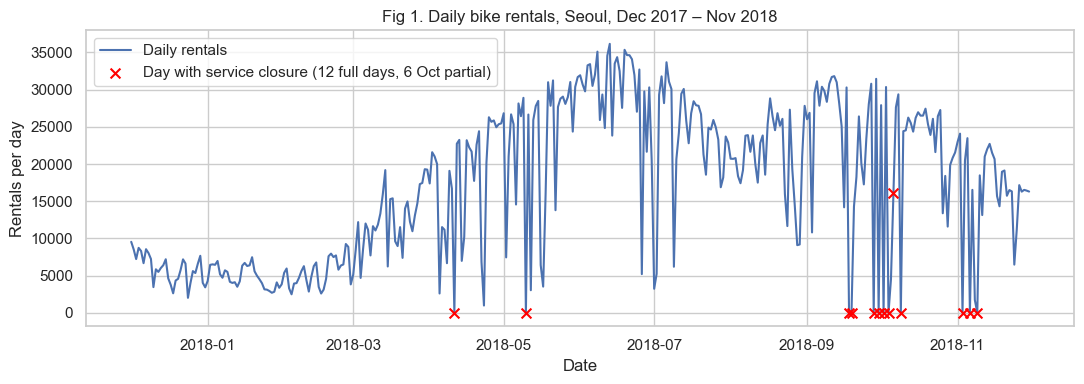

season
Autumn     924.0
Spring     746.0
Summer    1034.0
Winter     226.0
Name: count, dtype: float64


In [27]:
# Total rentals for each day
daily = df.groupby("date")["count"].sum()
# Dates when the service was closed
closed_days = df[df.functioning == "No"]["date"].unique()

plt.figure(figsize=(11, 4))
plt.plot(daily.index, daily.values, label="Daily rentals")
plt.scatter(closed_days, daily[closed_days], marker="x", color="red", s=50, zorder=3,
            label="Day with service closure (12 full days, 6 Oct partial)")
plt.title("Fig 1. Daily bike rentals, Seoul, Dec 2017 – Nov 2018")
plt.xlabel("Date")
plt.ylabel("Rentals per day")
plt.legend()
plt.tight_layout()
plt.savefig(FIG + "fig1_daily_series.png", dpi=200)
plt.show()
# Average hourly rentals in each season
print(op.groupby("season")["count"].mean().round(0))

**Fig 1 – interpretation**


- Strong seasonal pattern: mean hourly rentals are about 226 in winter versus about 1,034 in summer; the busiest day (13 Jun 2018) had 36,149 rentals.
  
- Sharp single-day drops (mostly rainy days) show that day-to-day variation is large even within a season.
  
- Service closures (×) affect 13 dates: 12 full days with zero rentals and one partial day (6 Oct 2018, 7 hours closed). Most fall in Sep–Nov 2018.


  
- **Implication:** observations close in time are dependent and demand changes over the year, so evaluation must be **chronological** (train on earlier months, test on later ones), not a random split (RQ1, RQ2).

### 3.2 Does the daily pattern differ between working days and other days? (Fig 2)

Purpose: check whether hour of day and day type interact → informs features (RQ1, RQ2) and motivates clustering of daily profiles (RQ3).

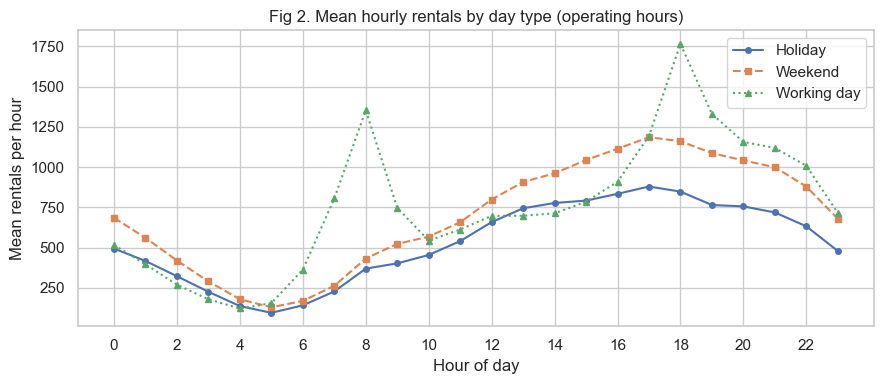


 day_type  Holiday  Weekend  Working day
hour                                   
8           369.0    432.0       1354.0
17          879.0   1186.0       1195.0
18          848.0   1161.0       1766.0


In [30]:
#| echo: false
#| output: true

prof = op.groupby(["day_type", "hour"])["count"].mean().reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
for (k, g), ls, m in zip(prof.groupby("day_type"), ["-", "--", ":"], ["o", "s", "^"]):
    ax.plot(g.hour, g["count"], ls=ls, marker=m, ms=4, label=k)
ax.set(title="Fig 2. Mean hourly rentals by day type (operating hours)", xlabel="Hour of day",
       ylabel="Mean rentals per hour", xticks=range(0, 24, 2))
ax.legend()
plt.tight_layout(); plt.savefig(FIG + "fig2_hourly_profile.png", dpi=200); plt.show()

print("\n", op.groupby(["day_type", "hour"])["count"].mean().unstack(0).loc[[8, 17, 18]].round(0))

**Fig 2 – interpretation**

- Working days show two **commuting peaks**: about 1,354 rentals at 08:00 and 1,766 at 18:00.
- Weekends and holidays show no morning peak and a single broad afternoon peak (about 1,190 at 17:00 at weekends).
- **Implication:** the effect of hour depends on day type (an interaction). Models need both, and tree-based models may capture this naturally (RQ1). The clearly different shapes suggest that days can be grouped into distinct usage patterns (RQ3).

### 3.3 How is demand associated with temperature and rain? (Fig 3)

Purpose: check the shape of weather associations → informs feature choice and model family (RQ1, RQ2).

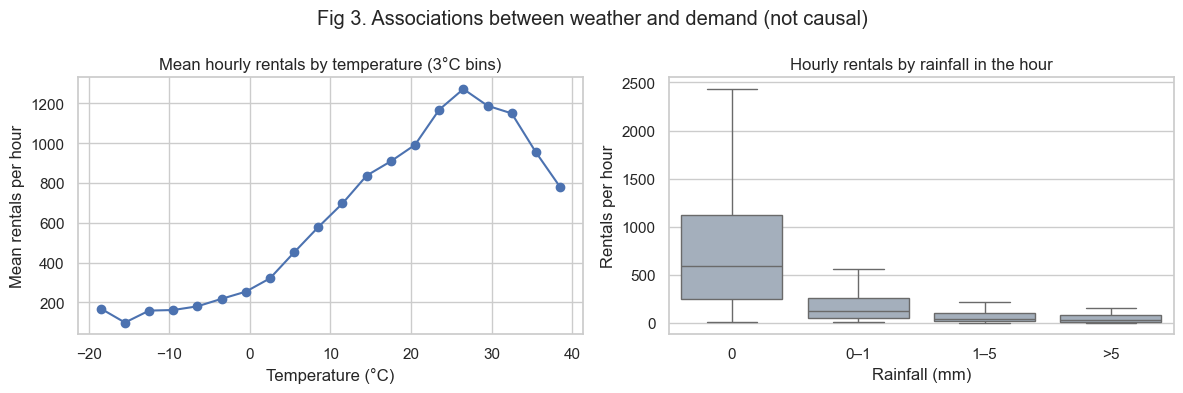

          median   mean  size
rain_cat                     
0          591.0  766.0  7949
0–1        123.0  224.0   274
1–5         38.0  114.0   178
>5          24.0   73.0    64


In [33]:
#| echo: false
#| output: true

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

op["temp_bin"] = pd.cut(op.temp, bins=range(-20, 42, 3))
t = op.groupby("temp_bin", observed=True)["count"].mean().reset_index()
t["mid"] = t.temp_bin.apply(lambda i: i.mid)
axes[0].plot(t["mid"], t["count"], marker="o")
axes[0].set(title="Mean hourly rentals by temperature (3°C bins)",
            xlabel="Temperature (°C)", ylabel="Mean rentals per hour")

op["rain_cat"] = pd.cut(op.rain, [-0.01, 0, 1, 5, 100], labels=["0", "0–1", "1–5", ">5"])
sns.boxplot(data=op, x="rain_cat", y="count", ax=axes[1], color="#a0aec0", showfliers=False)
axes[1].set(title="Hourly rentals by rainfall in the hour", xlabel="Rainfall (mm)", ylabel="Rentals per hour")

fig.suptitle("Fig 3. Associations between weather and demand (not causal)")
plt.tight_layout(); plt.savefig(FIG + "fig3_weather.png", dpi=200); plt.show()

print(op.groupby("rain_cat", observed=True)["count"].agg(["median", "mean", "size"]).round(0))

**Fig 3 – interpretation**

- Demand rises with temperature up to about 25–28 °C, then **falls** in the hottest hours → the association is **non-linear**, so a simple straight-line term is not enough (use transformations, splines or tree-based models).
- Median rentals fall from 591 per hour with no rain to 123 in light rain (0–1 mm) and 24 in heavy rain (>5 mm). Rain hours are rare (about 6 %) but associated with very low demand.
- **Implication:** weather variables are likely to improve predictions beyond calendar information (RQ1), and rain is relevant for anticipating unusually high or low demand (RQ2). This is consistent with previous reviews, which report temperature and precipitation among the strongest weather influences on bike-sharing use (Eren and Uz, 2020). These are associations; other factors (e.g. season, time of day) are also involved.

\newpage
### 3.4 What does the outcome distribution look like? (Fig 4)

Purpose: inform the choice of error metrics and transformation (RQ1), and show how a "high-demand" threshold could be defined (RQ2).

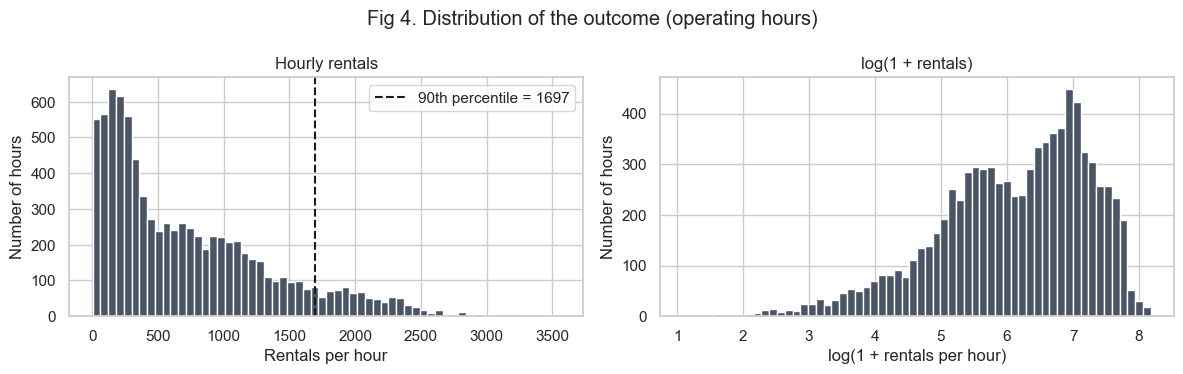

Skewness: 1.14 | 90th percentile: 1697.0


In [36]:
#| echo: false
#| output: true

q90 = op["count"].quantile(0.90)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(op["count"], bins=60, color="#4a5568")
axes[0].axvline(q90, ls="--", color="k", label=f"90th percentile = {q90:.0f}")
axes[0].set(title="Hourly rentals", xlabel="Rentals per hour", ylabel="Number of hours")
axes[0].legend()
axes[1].hist(np.log1p(op["count"]), bins=60, color="#4a5568")
axes[1].set(title="log(1 + rentals)", xlabel="log(1 + rentals per hour)", ylabel="Number of hours")
fig.suptitle("Fig 4. Distribution of the outcome (operating hours)")
plt.tight_layout(); plt.savefig(FIG + "fig4_target_dist.png", dpi=200); plt.show()

print("Skewness:", round(op["count"].skew(), 2), "| 90th percentile:", round(q90, 0))

**Fig 4 – interpretation**

- Hourly rentals are **right-skewed** (skewness 1.14): many quiet hours and a long tail of busy hours up to 3,556.
- The 90th percentile is about 1,697 rentals per hour (all data shown here, for illustration only).
- **Implication:** report both RMSE (penalises large errors at busy times) and MAE (typical error); consider a log-transformed outcome for linear regression (RQ1). In the final analysis the high-demand threshold for RQ2 must be set from the **training period only**, to avoid leakage.

### 3.5 Is demand similar to the same hour one week earlier? (Fig 5)

Purpose: check whether past demand at the same hour is a good guide → justifies the seasonal-naive baseline listed in Week 1 (RQ1).

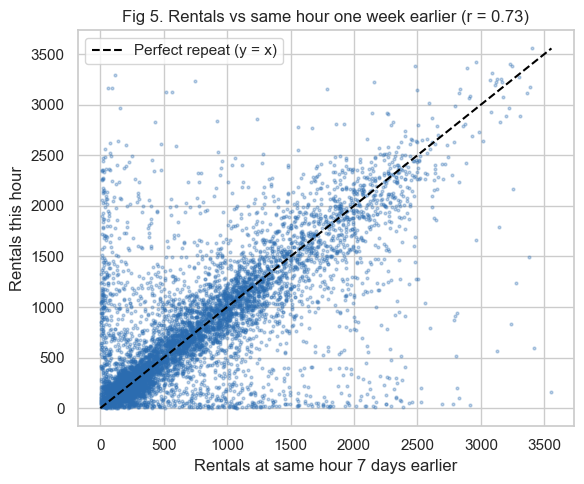

Correlation with same hour 1 week earlier: 0.732 | pairs used: 8026
rain
Dry hours       12.0
Rainy hours   -557.0
Name: diff, dtype: float64


In [39]:
#| echo: false
#| output: true

# Pair each hour with the same hour 7 days (168 hours) earlier

lagged = df.set_index("datetime")[["count", "functioning", "rain"]].copy()
lagged["count_lag168"] = lagged["count"].shift(168)
lagged["func_lag168"] = lagged["functioning"].shift(168)

# Keep only pairs where the service was operating in both weeks

lagged = lagged[(lagged.functioning == "Yes") & (lagged.func_lag168 == "Yes")].dropna()

# Correlation and scatter plot

r = lagged["count"].corr(lagged["count_lag168"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(lagged["count_lag168"], lagged["count"], s=4, alpha=0.3, color="#2b6cb0")
lim = [0, lagged["count"].max()]
ax.plot(lim, lim, ls="--", color="black", label="Perfect repeat (y = x)")
ax.set(title=f"Fig 5. Rentals vs same hour one week earlier (r = {r:.2f})",
       xlabel="Rentals at same hour 7 days earlier", ylabel="Rentals this hour")
ax.legend()
plt.tight_layout(); plt.savefig(FIG + "fig5_lag_scatter.png", dpi=200); plt.show()
print("Correlation with same hour 1 week earlier:", round(r, 3), "| pairs used:", len(lagged))

# Median change vs same hour last week: dry vs rainy hours
lagged["diff"] = lagged["count"] - lagged["count_lag168"]
print(lagged.groupby(lagged.rain > 0)["diff"].median().rename({False: "Dry hours", True: "Rainy hours"}))

\newpage

**Fig 5 – interpretation**

- Rentals are strongly correlated with rentals at the same hour one week earlier (r = 0.73, 8,026 hour pairs), and points cluster around the y = x line.
- The spread around the line shows that past demand alone misses weather-driven changes: in rainy hours, rentals are typically about 557 lower than at the same hour one week earlier, whereas dry hours are almost unchanged (median difference +12).
- **Implication:** a **seasonal-naive baseline** (predict last week's value for the same hour) is a meaningful benchmark for RQ1, and weather features are needed to improve on it. Hours where either week was a closure are excluded.

### 3.6 Are the weather variables correlated with each other? (Fig 6)

Purpose: identify collinearity that affects interpretation of linear models.

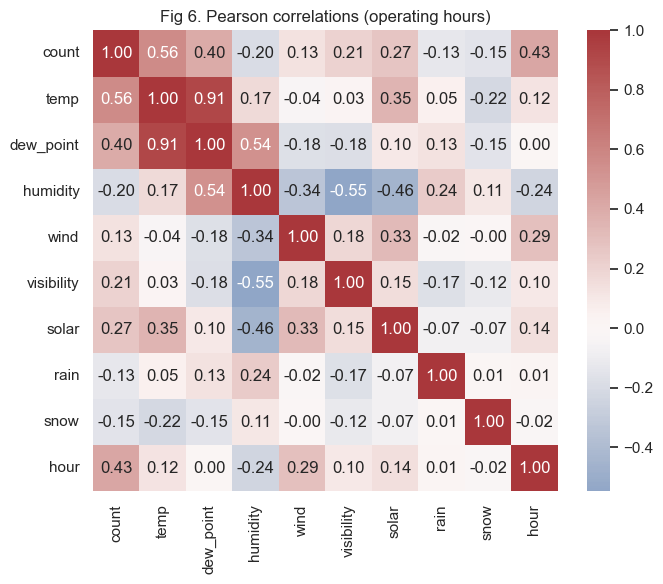

In [42]:
#| echo: false
#| output: true

num = ["count", "temp", "dew_point", "humidity", "wind", "visibility", "solar", "rain", "snow", "hour"]
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(op[num].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Fig 6. Pearson correlations (operating hours)")
plt.tight_layout(); plt.savefig(FIG + "fig6_corr.png", dpi=200); plt.show()

**Fig 6 – interpretation**

- Temperature and dew point are strongly correlated (r = 0.91), and humidity is negatively related to visibility and solar radiation.
- **Implication:** in linear models, keep only one of temperature and dew point (or use regularisation) so coefficients remain interpretable. Tree-based models are less affected.

## 4. Research questions

The three questions form one investigation: **supporting the bike-share operator's short-term planning**. RQ3 describes the underlying usage patterns, RQ1 predicts how much demand to expect, and RQ2 turns predictions into an operational warning for exceptionally busy hours. RQ1 and RQ2 require data modelling; RQ3 uses a broader (unsupervised) data-science approach.

### RQ1 – Predicting hourly demand (regression / forecasting)
\begin{rqbox}
\textbf{How accurately can hourly bike rentals in Seoul be predicted one day ahead using calendar and weather information, and how much do weather variables improve accuracy beyond calendar patterns and last week's demand?}
\end{rqbox}

- **Why it matters:** the operator schedules bike redistribution and staff in advance; better hourly predictions reduce empty or overfull stations and wasted vehicle trips.
- **Why it is answerable:** the outcome (Rented Bike Count) is recorded every hour; calendar variables are known in advance; weather is available (observed weather is used as a stand-in for forecasts – an assumption stated explicitly). Strong weekly repetition (Fig 5, r = 0.73) gives a meaningful seasonal-naive baseline, and the strong but non-linear weather associations (Fig 3) suggest models can improve on it.
- **Evidence:** Figs 1, 2, 3, 5.

### RQ2 – Anticipating high-demand hours (classification)
\begin{rqbox}
\textbf{Can hours of exceptionally high demand (above the 90th percentile of the training period) be identified one day in advance from calendar and weather information, and what decision threshold best balances missed peaks against false alarms?}
\end{rqbox}

- **Why it matters:** peak hours are when shortages occur and extra redistribution is most valuable; the operator needs a clear yes/no warning, and the cost of missing a peak differs from the cost of a false alarm.
- **Why it is answerable:** a binary outcome can be derived from Rented Bike Count (about 10 % of hours by construction); peaks are concentrated in working-day commuting hours and warm, dry weather (Figs 2–3), so the predictors carry relevant information. The threshold will be fixed on training data only to avoid leakage.
- **Evidence:** Figs 2, 3, 4.

### RQ3 – Typical daily usage patterns (clustering)
\begin{rqbox}
\textbf{What distinct daily patterns of bike use occur across the year, and how are they associated with day type, season and weather?}
\end{rqbox}

- **Why it matters:** recognisable day types (e.g. "commuter day", "leisure day", "low-use winter or rainy day") give the operator simple planning templates and show where prediction models are likely to struggle.
- **Why it is answerable:** each fully operating day provides a 24-hour demand profile (number checked below); Fig 2 already shows clearly different shapes for working days and weekends, suggesting real structure; day type, season and weather are available to describe the resulting groups.
- **Evidence:** Figs 1, 2.

In [48]:
#| echo: false
#| output: false

closed_days = df[df.functioning == "No"].date.unique()
print("Total days:", df.date.nunique(),
      "| days with any closure:", len(closed_days),
      "| fully operating days for RQ3:", df.date.nunique() - len(closed_days))

Total days: 365 | days with any closure: 13 | fully operating days for RQ3: 352


**Findings – Section 4**

- 352 fully operating days are available as 24-hour profiles for RQ3.
- All three questions concern **prediction or association**. They do not claim that weather or calendar factors *cause* changes in demand, because the data are observational.

## 5. Provisional analysis plan

Data are split **by time** (Week 1; Hyndman and Athanasopoulos, 2021): train Dec 2017 – Aug 2018, validation Sep 2018, test Oct – Nov 2018. A random split would leak future information. The seasonal-naive baseline follows standard forecasting practice (Hyndman and Athanasopoulos, 2021). Models are not fitted in Assessment 1.

In [79]:
#| echo: false
#| output: true

op["split"] = np.where(op.date <= "2018-08-31", "train",
               np.where(op.date <= "2018-09-30", "validation", "test"))

# RQ2 threshold from training data only (avoids leakage)
threshold = op.loc[op.split == "train", "count"].quantile(0.90)
op["high_demand"] = (op["count"] > threshold).astype(int)

print("High-demand threshold:", round(threshold), "rentals per hour")
op.groupby("split").agg(hours=("count", "size"), mean_rentals=("count", "mean"),
                        high_demand_share=("high_demand", "mean")).round(3).loc[["train", "validation", "test"]]

High-demand threshold: 1646 rentals per hour


,hours,mean_rentals,high_demand_share
split,,,
train,6528,671.310,0.100
validation,624,1079.506,0.208
test,1313,850.259,0.097


| | **RQ1 – Hourly demand** | **RQ2 – High-demand warning** | **RQ3 – Daily patterns** |
|---|---|---|---|
| **Outcome** | Rentals per hour | High demand (count > training 90th percentile = 1,646) | None – 24-hour profile of each fully operating day (352 days) |
| **Features** | Hour, day of week, holiday, weather, rentals same hour last week (not season/month – see below) | Same as RQ1 | 24 hourly counts, each standardised to mean 0, SD 1 (Week 4); then described by day type, season, weather |
| **Baseline** | Same hour last week (seasonal naive) | Rule: working-day peak hour (07–09, 17–19) with no rain | Grouping by day type |
| **Comparisons** | Model A: calendar only → Model B: calendar + weather → Model C: calendar + weather + last week's rentals | Logistic regression vs decision tree vs baseline rule | K-means for k = 2–8 vs day-type grouping |
| **Methods** | Linear regression, decision tree, random forest | Logistic regression, decision tree | K-means |
| **Evaluation** | MAE and RMSE on the same test hours; the A→B gain answers "how much weather adds" | Precision, recall, F1; decision threshold chosen on validation only; test used once | Elbow, silhouette, stability across 10 random seeds, practical interpretation |

Same-hour or same-day rentals are **excluded** as features (not known a day ahead).

**Forecast set-up (RQ1, RQ2):** predictions are made at the end of day *D−1* for each of the 24 hours of day *D*. Available at that time: calendar variables, rentals from the same hour one week earlier, and weather. Observed weather is used as a **proxy for the next-day forecast**; because real forecasts contain errors, results will be optimistic, and this is stated as a limitation.

**Seasonal coverage:** the training period (Dec–Aug) contains no autumn months, while validation and test (Sep–Nov) are all autumn. `season` and `month` therefore cannot be used directly as features (their autumn values are never seen in training); temperature, daylight-related weather and last week's rentals carry this information instead. Assessment 3 will also use rolling-origin evaluation so that later folds train on some autumn data.

**Findings – Section 5**

- Train 6,528 hours, validation 624, test 1,313. High-demand threshold = 1,646 rentals per hour.
- High-demand hours: 10 % of training, **21 % of validation**, 10 % of test. September is a warm, busy month (mean 1,080 rentals per hour) from a season absent from training, so the share of busy hours shifts between periods. Accuracy alone would mislead; precision and recall will be reported per period.
- The test period covers autumn only; Assessment 3 will check stability with rolling evaluation.

\newpage

## 6. Limitations and responsible use

**Generalisability**


- One city (Seoul) and one year (Dec 2017 – Nov 2018), before COVID-19 changed travel patterns. Results should not be assumed to hold for other cities or later years without re-checking.
- The test period (Oct–Nov) covers autumn only and includes about half of the closure hours, so test results may not represent winter or summer.

**Measurement**


- The outcome is **recorded rentals**, not true demand: when stations are empty, demand is not observed, so busy periods may be under-estimated.
- Data are city-wide hourly totals: no station, trip or user information, so no conclusions about specific areas or people are possible.
- Data-quality issues were found and handled: 295 closed hours excluded, 17 impossible humidity values interpolated, visibility capped at 20 km.

**Leakage and over-optimism**


- Observed weather is used as a stand-in for forecasts; real forecasts contain errors, so real-world accuracy is likely to be lower.
- Same-day rentals are excluded as features, and the RQ2 threshold is set from training data only.
- Humidity gaps were filled using neighbouring (including later) hours; Assessment 3 will use past values only.

**Interpretation**


- The data are observational. Results describe **associations and predictions**, not causal effects of weather or holidays on cycling.

**Ethics, equality, diversity and inclusion (EDI)**


- The data contain no personal information, so privacy risk is low.
- Bike-share users are not representative of the whole population: users tend to have higher incomes and education, and men make more trips than women (Fishman, 2016). Older people, disabled people and those without smartphones or payment cards may be under-represented, and standard bikes are not accessible to everyone.
- Planning based on total demand could direct bikes and staff towards busy commuter areas and away from less-served districts, reinforcing existing inequalities. City-wide data cannot reveal this, so predictions should support, not replace, decisions that consider fair coverage.

**Sustainability**


- Bike-sharing can reduce car use and emissions, but only if it replaces car trips rather than walking or public transport, which these data cannot show.
- Redistribution vans produce emissions; better predictions could reduce unnecessary trips.
- Simple, interpretable models are preferred unless more complex ones clearly improve on them, which keeps computing cost low and makes the models easier to maintain and retrain as patterns change.

\newpage

## 7. References

Eren, E. and Uz, V.E. (2020) 'A review on bike-sharing: The factors affecting bike-sharing demand', *Sustainable Cities and Society*, 54, 101882.

Fishman, E. (2016) 'Bikeshare: A review of recent literature', *Transport Reviews*, 36(1), pp. 92–113.

Hyndman, R.J. and Athanasopoulos, G. (2021) *Forecasting: Principles and Practice*. 3rd edn. Melbourne: OTexts. Available at: https://otexts.com/fpp3/ (Accessed: 27 October 2026).

UCI Machine Learning Repository (2020) *Seoul Bike Sharing Demand* [dataset]. Available at: https://doi.org/10.24432/C5F62R (Accessed: 27 October 2026).

In [58]:
#| echo: false
#| output: false

### Save cleaned data (for Assessment 3)

os.makedirs("data_processed", exist_ok=True)
df.to_csv("data_processed/seoul_bike_clean.csv", index=False)
op.to_csv("data_processed/seoul_bike_operating_hours.csv", index=False)
print("Saved:", df.shape, "all hours |", op.shape, "operating hours")

Saved: (8760, 20) all hours | (8465, 24) operating hours


## Appendix: Generative AI Integrity Form

**Group:** PG-18

**Date of submission:** 30 October 2026

- I acknowledge the use of Claude (Anthropic), https://claude.ai, to explain unfamiliar concepts and suggest an outline structure for this report (Sections 1–7). The explanations were checked against the Project Guide and the lecture notes (Weeks 1–4).

- I acknowledge the use of Claude (Anthropic), https://claude.ai, to suggest and debug Python code for data checks and figures (Sections 1–5, Figures 1–6). All cells were run by the group with Restart and Run All, and the outputs were checked against the raw data.

- I acknowledge the use of Claude (Anthropic), https://claude.ai, to suggest wording and identify improvements in writing style (Sections 1–6 and the research questions). The group edited the text in its own words, and every number was checked against the notebook outputs.

- I acknowledge the use of Claude (Anthropic), https://claude.ai, to advise on the PDF format and layout of this report. The final version was checked and agreed by all group members.

### Declaration

No content generated by AI technologies has been presented as our own work without being checked and understood by the group. All analysis, interpretation and conclusions can be explained and reproduced by every member.

**Group members:** Thaheer - tsb30; Tiffany - tat13; Kavya - skrd1; Rahmath - rp579; Venkateswara - vrk8; Dushyanth - dy86

**Dated:** 30 October 2026